In [1]:
import numpy as np
import pandas as pd
import seaborn as sns 
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.linear_model import LinearRegression

In [3]:
data = pd.read_csv(r"C:\Users\Hp\Desktop\ML and DL\insurance.csv")

In [5]:
data

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


In [7]:
data.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

## Starting with categorical features
 sex, smoker, region

sex
male      676
female    662
Name: count, dtype: int64


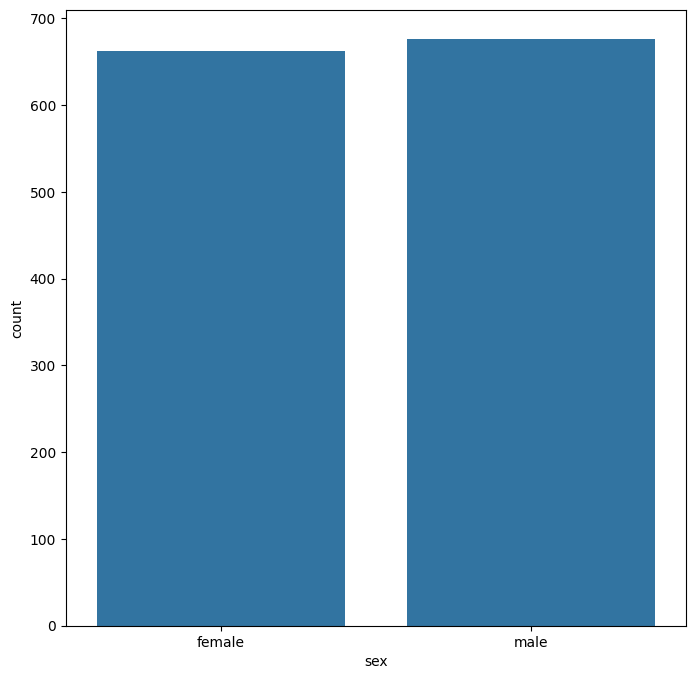

In [10]:
print(data["sex"].value_counts())
plt.figure(figsize=(8,8))
sns.countplot(x="sex",data=data)
plt.show()

smoker
no     1064
yes     274
Name: count, dtype: int64


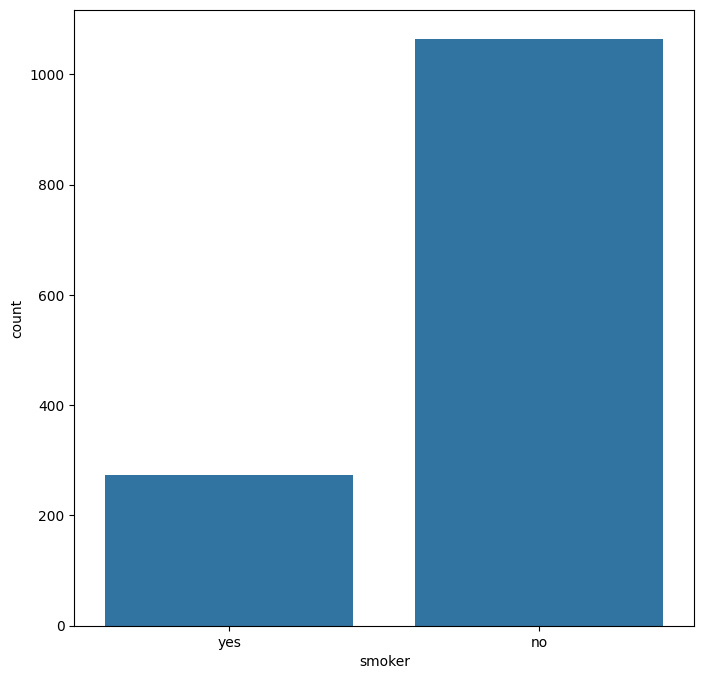

In [12]:
print(data["smoker"].value_counts())
plt.figure(figsize=(8,8))
sns.countplot(x="smoker",data=data)
plt.show()

region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64


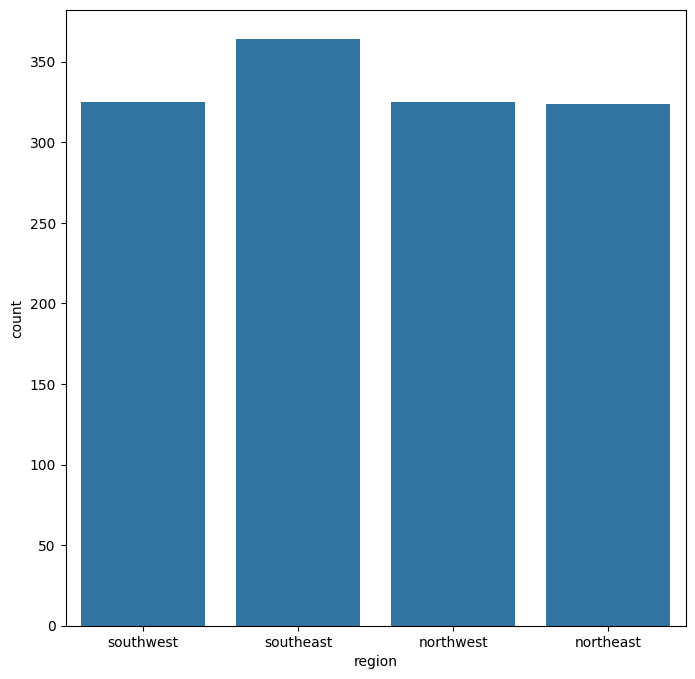

In [14]:
print(data["region"].value_counts())
plt.figure(figsize=(8,8))
sns.countplot(x="region",data=data)
plt.show()

### numerical Features

<Figure size 800x800 with 0 Axes>

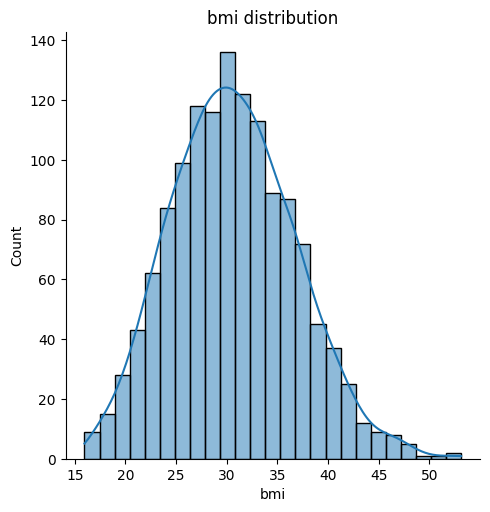

In [17]:
#bmi         
plt.figure(figsize=(8,8))
sns.displot(data["bmi"],kde=True)
plt.title("bmi distribution")
plt.show()

In [19]:
edit_data = data.replace({"smoker":{"no":0,"yes":1},"sex":{"female":0,"male":1},"region":{"southeast":0,"northeast":1,"southwest":2,"northwest":3}})
edit_data

C:\Users\Hp\AppData\Local\Temp\ipykernel_10464\3922441651.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  edit_data = data.replace({"smoker":{"no":0,"yes":1},"sex":{"female":0,"male":1},"region":{"southeast":0,"northeast":1,"southwest":2,"northwest":3}})


,age,sex,bmi,children,smoker,region,charges
0,19,0,27.900,0,1,2,16884.92400
1,18,1,33.770,1,0,0,1725.55230
2,28,1,33.000,3,0,0,4449.46200
3,33,1,22.705,0,0,3,21984.47061
4,32,1,28.880,0,0,3,3866.85520
...,...,...,...,...,...,...,...
1333,50,1,30.970,3,0,3,10600.54830
1334,18,0,31.920,0,0,1,2205.98080
1335,18,0,36.850,0,0,0,1629.83350
1336,21,0,25.800,0,0,2,2007.94500


In [21]:
X = edit_data.drop(columns="charges",axis=1)
Y = edit_data["charges"]
x_train , x_test , y_train , y_test = train_test_split(X,Y,test_size=0.2 ,random_state=2)
print(x_train.shape,x_test.shape)
#X["sex"].value_counts()
data["charges"].mean()

(1070, 6) (268, 6)


np.float64(13270.422265141257)

In [23]:
# from xgboost import XGBRegressor
# from sklearn.svm import SVR

model = LinearRegression()
model.fit(x_train,y_train)
x_prediction_train = model.predict(x_train)
print("R_squared for x_train prediction : ", metrics.r2_score(x_prediction_train,y_train))
print("absolute mean error for x_train prediction : ",metrics.mean_absolute_error(x_prediction_train,y_train))

R_squared for x_train prediction :  0.6686994577004692
absolute mean error for x_train prediction :  4152.4109799088


In [25]:
x_prediction_test = model.predict(x_test)
print("R_squared for x_train prediction : ", metrics.r2_score(x_prediction_test,y_test))
print("absolute mean error for x_train prediction : ",metrics.mean_absolute_error(x_prediction_test,y_test))

R_squared for x_train prediction :  0.6583811860355423
absolute mean error for x_train prediction :  4261.438318476059


In [29]:
import pickle 
x = open("Medical_Insurance.pkl","wb")
pickle.dump(model,x)